# Assignment 9

## Experiment 1: Realisation of Confusion Matrix and Performance Metrics

In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
cm = np.array([
    [40, 2, 3, 1, 4],
    [ 5, 35, 2, 3, 5],
    [ 2, 4, 38, 3, 3],
    [ 1, 2, 4, 42, 1],
    [ 3, 5, 2, 1, 39]
])

classes = ['A', 'B', 'C', 'D', 'E']

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[40  2  3  1  4]
 [ 5 35  2  3  5]
 [ 2  4 38  3  3]
 [ 1  2  4 42  1]
 [ 3  5  2  1 39]]


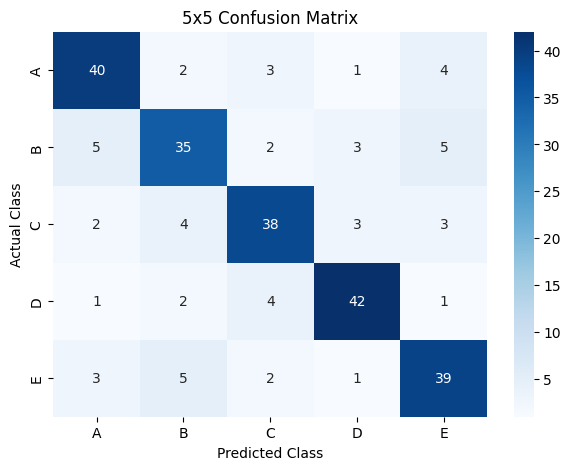

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("5x5 Confusion Matrix")
plt.show()

In [ ]:
total = cm.sum()

metrics = []

for i, cls in enumerate(classes):

    TP = cm[i, i]
    FN = cm[i, :].sum() - TP
    FP = cm[:, i].sum() - TP
    TN = total - TP - FN - FP

    metrics.append({
        'Class': cls,
        'TP': TP,
        'TN': TN,
        'FP': FP,
        'FN': FN
    })

metrics_df = pd.DataFrame(metrics)

print(metrics_df)

  Class  TP   TN  FP  FN
0     A  40  189  11  10
1     B  35  187  13  15
2     C  38  189  11  12
3     D  42  192   8   8
4     E  39  187  13  11


In [ ]:
results = []

for i, cls in enumerate(classes):

    TP = cm[i, i]
    FN = cm[i, :].sum() - TP
    FP = cm[:, i].sum() - TP
    TN = total - TP - FN - FP

    accuracy = (TP + TN) / total
    precision = TP / (TP + FP)
    recall = TP / (TP + FN)
    specificity = TN / (TN + FP)
    f1 = 2 * precision * recall / (precision + recall)
    error_rate = 1 - accuracy

    results.append({
        'Class': cls,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'Specificity': specificity,
        'F1 Score': f1,
        'Error Rate': error_rate
    })

results_df = pd.DataFrame(results)

print("Performance Metrics for Each Class:")
display(results_df.round(4))

Performance Metrics for Each Class:


,Class,Accuracy,Precision,Recall,Specificity,F1 Score,Error Rate
0,A,0.916,0.7843,0.80,0.945,0.7921,0.084
1,B,0.888,0.7292,0.70,0.935,0.7143,0.112
2,C,0.908,0.7755,0.76,0.945,0.7677,0.092
3,D,0.936,0.8400,0.84,0.960,0.8400,0.064
4,E,0.904,0.7500,0.78,0.935,0.7647,0.096


In [ ]:
y_true = []
y_pred = []

for i in range(len(classes)):
    for j in range(len(classes)):
        y_true.extend([classes[i]] * cm[i, j])
        y_pred.extend([classes[j]] * cm[i, j])

overall_accuracy = accuracy_score(y_true, y_pred)

macro_precision = precision_score(
    y_true, y_pred, average='macro'
)

macro_recall = recall_score(
    y_true, y_pred, average='macro'
)

macro_f1 = f1_score(
    y_true, y_pred, average='macro'
)

print("Overall Accuracy:", round(overall_accuracy, 4))
print("Macro Precision:", round(macro_precision, 4))
print("Macro Recall:", round(macro_recall, 4))
print("Macro F1 Score:", round(macro_f1, 4))

Overall Accuracy: 0.776
Macro Precision: 0.7758
Macro Recall: 0.776
Macro F1 Score: 0.7757


## Experiment 2: Classification using KNN and SVM

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.datasets import mnist

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


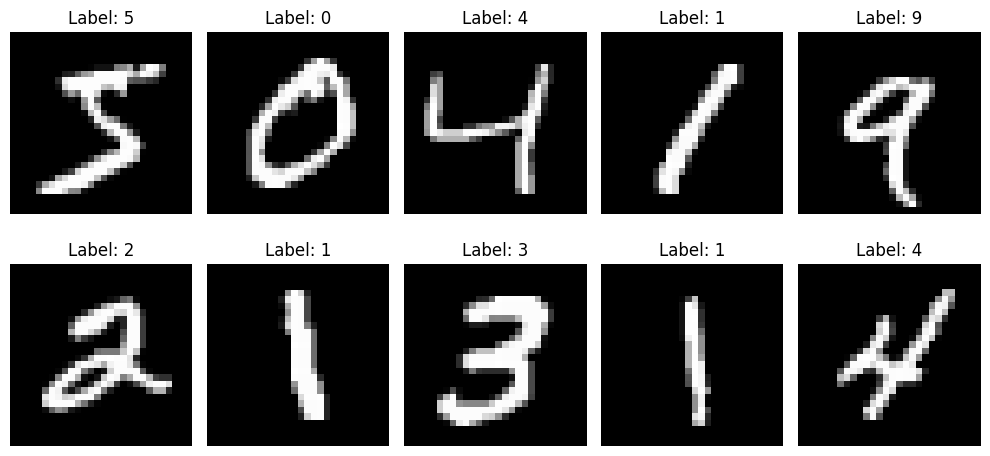

In [ ]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# Flatten images into 784 features
X_train = X_train.reshape(X_train.shape[0], 784)
X_test = X_test.reshape(X_test.shape[0], 784)

# Normalize pixel values
X_train = X_train / 255.0
X_test = X_test / 255.0

# Select subset for faster execution
X_train = X_train[:10000]
y_train = y_train[:10000]

X_test = X_test[:2000]
y_test = y_test[:2000]

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

Training samples: (10000, 784)
Testing samples: (2000, 784)


In [ ]:
knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

print("KNN Classification Completed!")

KNN Classification Completed!


In [ ]:
print("KNN Performance Metrics")

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn, average='weighted'))
print("Recall:", recall_score(y_test, y_pred_knn, average='weighted'))
print("F1 Score:", f1_score(y_test, y_pred_knn, average='weighted'))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

KNN Performance Metrics
Accuracy: 0.9235
Precision: 0.9246672275751828
Recall: 0.9235
F1 Score: 0.922867861065958

Classification Report:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97       175
           1       0.90      1.00      0.95       234
           2       0.98      0.89      0.93       219
           3       0.91      0.91      0.91       207
           4       0.94      0.94      0.94       217
           5       0.91      0.91      0.91       179
           6       0.95      0.97      0.96       178
           7       0.89      0.91      0.90       205
           8       0.95      0.80      0.87       192
           9       0.89      0.90      0.89       194

    accuracy                           0.92      2000
   macro avg       0.92      0.92      0.92      2000
weighted avg       0.92      0.92      0.92      2000



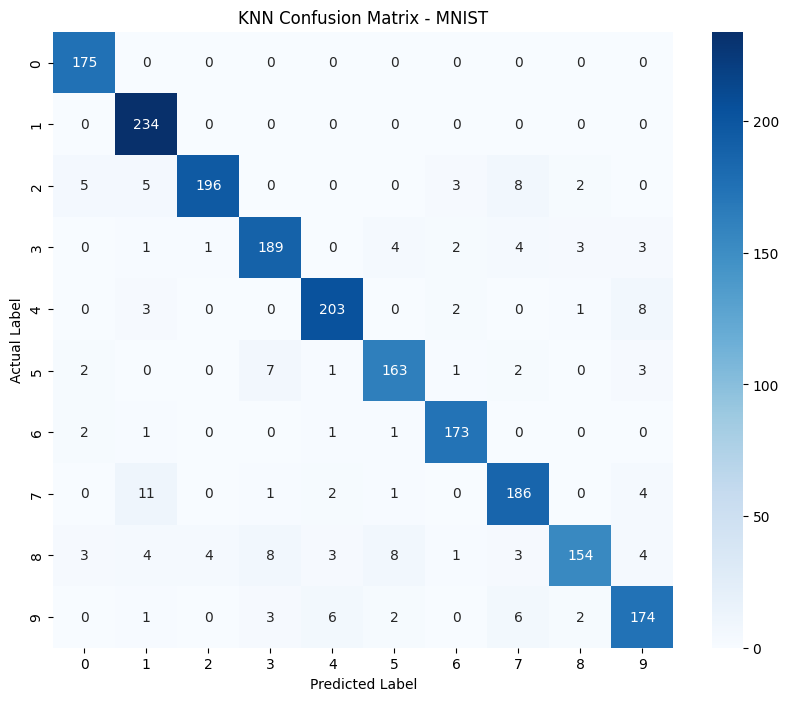

In [ ]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("KNN Confusion Matrix - MNIST")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [ ]:
svm = SVC(kernel='rbf')

svm.fit(X_train, y_train)

y_pred_svm = svm.predict(X_test)

print("SVM Classification Completed!")

SVM Classification Completed!


In [ ]:
print("SVM Performance Metrics")

print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm, average='weighted'))
print("Recall:", recall_score(y_test, y_pred_svm, average='weighted'))
print("F1 Score:", f1_score(y_test, y_pred_svm, average='weighted'))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Performance Metrics
Accuracy: 0.9445
Precision: 0.9443434637614317
Recall: 0.9445
F1 Score: 0.9443289532945617

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.97       175
           1       0.97      0.99      0.98       234
           2       0.95      0.96      0.95       219
           3       0.92      0.92      0.92       207
           4       0.95      0.95      0.95       217
           5       0.95      0.93      0.94       179
           6       0.94      0.96      0.95       178
           7       0.93      0.91      0.92       205
           8       0.95      0.92      0.93       192
           9       0.93      0.91      0.92       194

    accuracy                           0.94      2000
   macro avg       0.94      0.94      0.94      2000
weighted avg       0.94      0.94      0.94      2000



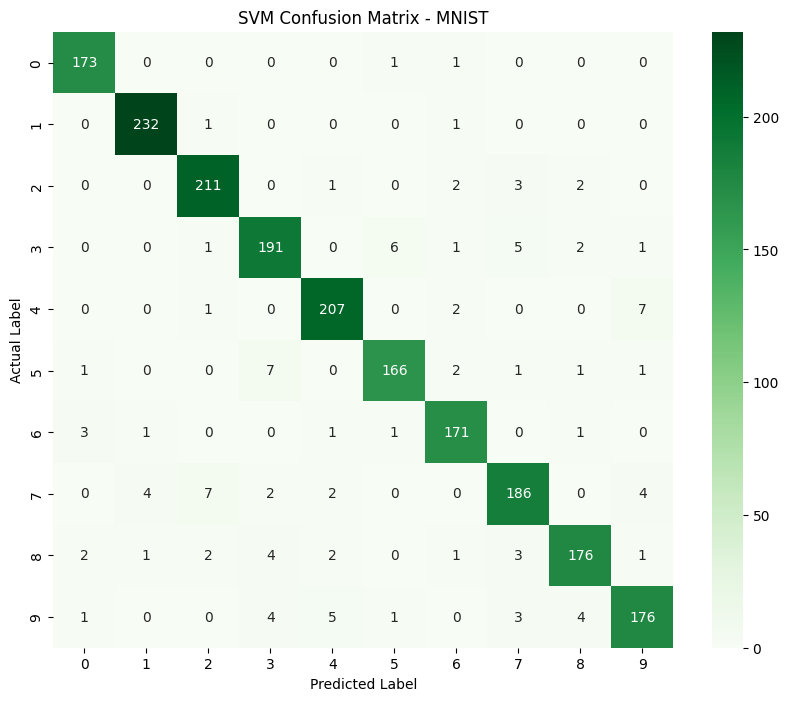

In [ ]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("SVM Confusion Matrix - MNIST")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [ ]:
comparison_mnist = pd.DataFrame({
    'Algorithm': ['KNN', 'SVM'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm)
    ],
    'Precision': [
        precision_score(y_test, y_pred_knn, average='weighted'),
        precision_score(y_test, y_pred_svm, average='weighted')
    ],
    'Recall': [
        recall_score(y_test, y_pred_knn, average='weighted'),
        recall_score(y_test, y_pred_svm, average='weighted')
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_knn, average='weighted'),
        f1_score(y_test, y_pred_svm, average='weighted')
    ]
})

display(comparison_mnist.round(4))

,Algorithm,Accuracy,Precision,Recall,F1 Score
0,KNN,0.9235,0.9247,0.9235,0.9229
1,SVM,0.9445,0.9443,0.9445,0.9443
